In [92]:
print("SVM Project Started Successfully!")

SVM Project Started Successfully!


In [93]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# SVM model
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [94]:
# Load the Breast Cancer dataset
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

# Separate features and target
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# Display dataset information
print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nTarget classes:")
print(data.target_names)

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

Dataset loaded successfully!
Number of rows: 569
Number of features: 30

Target classes:
['malignant' 'benign']

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


In [95]:
# Check dataset structure
print("Dataset Shape:", X.shape)

print("\nColumn Names:")
print(X.columns.tolist())

print("\nDataset Information:")
X.info()

print("\nStatistical Summary:")
display(X.describe())

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nDuplicate Rows:")
print(X.duplicated().sum())

Dataset Shape: (569, 30)

Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-nul

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500



Missing Values:
0

Duplicate Rows:
0


Malignant (0): 212
Benign (1): 357


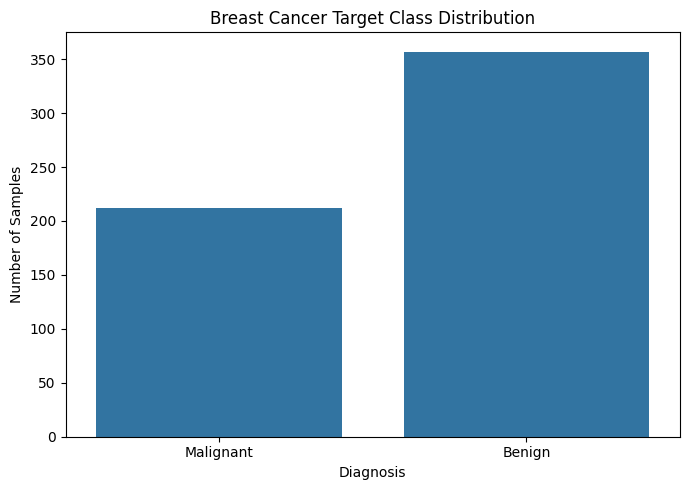

In [96]:
# Count target classes
target_counts = y.value_counts().sort_index()

print("Malignant (0):", target_counts[0])
print("Benign (1):", target_counts[1])

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(x=y.map({0: "Malignant", 1: "Benign"}))

plt.title("Breast Cancer Target Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [97]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed successfully!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)

Feature scaling completed successfully!
Scaled training shape: (455, 30)
Scaled testing shape: (114, 30)


In [98]:
# Create the SVM classifier
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train the model
svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [99]:
# Predict using the trained SVM model
y_pred = svm_model.predict(X_test_scaled)

print("Predictions completed successfully!")
print("\nFirst 10 actual values:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 actual values:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 predicted values:
[0 1 0 1 0 1 1 0 0 0]


Test Accuracy: 98.25%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
[[41  1]
 [ 1 71]]


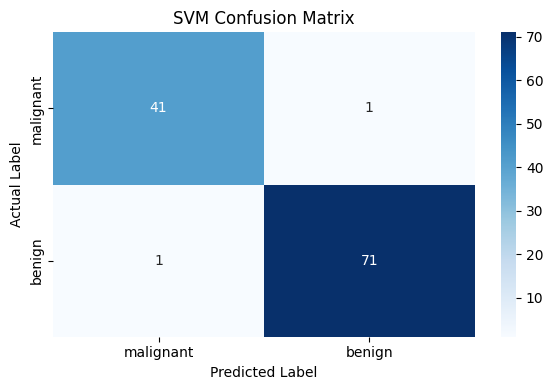

In [100]:
# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [101]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Create a pipeline to scale features and train SVM
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

# Parameters to test
param_grid = {
    "svm__C": [0.1, 1, 10],
    "svm__kernel": ["linear", "rbf"],
    "svm__gamma": ["scale", "auto"]
}

# Perform 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print(f"\nBest Cross-Validation Accuracy: "
      f"{grid_search.best_score_ * 100:.2f}%")

Best Parameters:
{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

Best Cross-Validation Accuracy: 97.80%


Original SVM Test Accuracy: 98.25%
Tuned SVM Test Accuracy:    98.25%

Tuned Model Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Tuned Model Confusion Matrix:
[[41  1]
 [ 1 71]]


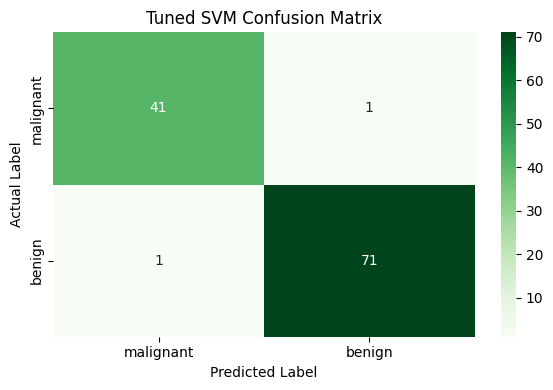

In [102]:
# Get the best tuned model
best_svm_model = grid_search.best_estimator_

# Predict on the test set
y_pred_tuned = best_svm_model.predict(X_test)

# Calculate tuned model accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print(f"Original SVM Test Accuracy: {accuracy * 100:.2f}%")
print(f"Tuned SVM Test Accuracy:    {tuned_accuracy * 100:.2f}%")

print("\nTuned Model Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=data.target_names,
        zero_division=0
    )
)

# Confusion matrix for tuned model
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Tuned Model Confusion Matrix:")
print(cm_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Tuned SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [103]:
print("===== SVM MODEL COMPARISON =====")

print(f"Original SVM Test Accuracy: {accuracy * 100:.2f}%")
print(f"Tuned SVM Test Accuracy:    {tuned_accuracy * 100:.2f}%")

print("\nBest Hyperparameters:")
print(grid_search.best_params_)

print(f"\nBest Cross-Validation Accuracy: "
      f"{grid_search.best_score_ * 100:.2f}%")

print("\nDid tuning improve test accuracy?")
if tuned_accuracy > accuracy:
    print("Yes, test accuracy improved.")
elif tuned_accuracy < accuracy:
    print("No, test accuracy decreased.")
else:
    print("No change in test accuracy.")

===== SVM MODEL COMPARISON =====
Original SVM Test Accuracy: 98.25%
Tuned SVM Test Accuracy:    98.25%

Best Hyperparameters:
{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

Best Cross-Validation Accuracy: 97.80%

Did tuning improve test accuracy?
No change in test accuracy.


In [104]:
import joblib
from pathlib import Path

# Create a folder for saved models
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the complete tuned pipeline
joblib.dump(
    best_svm_model,
    model_dir / "svm_breast_cancer_model.pkl"
)

print("Tuned SVM model saved successfully!")
print("File: models/svm_breast_cancer_model.pkl")

Tuned SVM model saved successfully!
File: models/svm_breast_cancer_model.pkl


In [105]:
# Load the saved SVM model
import joblib

loaded_model = joblib.load(
    "models/svm_breast_cancer_model.pkl"
)

# Predict five test samples
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Saved model loaded successfully!")
print("\nPredictions:")

for i, prediction in enumerate(sample_predictions):
    diagnosis = data.target_names[prediction]
    print(f"Sample {i + 1}: {diagnosis}")

Saved model loaded successfully!

Predictions:
Sample 1: malignant
Sample 2: benign
Sample 3: malignant
Sample 4: benign
Sample 5: malignant
